# 📊 Redes sociales: ¿el impacto es igual para todos los estudiantes?

**Laboratorio de Métodos Cuantitativos Aplicados a la Gestión · FCE UBA**
**Trabajo práctico grupal**

---

**Objetivo general:** analizar el impacto del uso de redes sociales sobre los estudiantes —en términos de **tiempo de uso**, **horas de sueño**, **salud mental** y **rendimiento académico percibido**— e identificar si ese impacto difiere entre grupos.

Para ello se plantean las siguientes preguntas de investigación:

| # | Pregunta | Sección |
|---|---|---|
| 1 | ¿Existen diferencias en el impacto según la **edad** del estudiante? | 4 |
| 2 | ¿Existen diferencias entre estudiantes de **países con distinto nivel de desarrollo**? | 5 |
| 3 | ¿El uso de redes sociales repercute en las **horas de sueño**? | 6 |
| 4 | ¿Existe un impacto en el **rendimiento académico** asociado al uso de redes y al sueño? | 6 |
| 5 | ¿Hay **redes sociales** que impactan más que otras? | 7 |
| 6 | ¿Existe una **brecha de género** en ese impacto? | 7 |

Cada pregunta se aborda con un análisis exploratorio: limpieza y transformación de variables, estadística descriptiva por grupos y visualizaciones, acompañadas de su interpretación.

## Índice

0. [Resumen ejecutivo](#0-resumen-ejecutivo)
1. [Preparación del entorno y carga de datos](#1-preparacion-del-entorno-y-carga-de-datos)
2. [Exploración inicial y calidad de los datos](#2-exploracion-inicial-y-calidad-de-los-datos)
3. [Limpieza común y criterios metodológicos](#3-limpieza-comun-y-criterios-metodologicos)
4. [Pregunta 1 · Impacto según la edad](#4-pregunta-1-impacto-segun-la-edad)
5. [Pregunta 2 · Impacto según el nivel de desarrollo del país](#5-pregunta-2-impacto-segun-el-nivel-de-desarrollo-del-pais)
6. [Preguntas 3 y 4 · Sueño y rendimiento académico](#6-preguntas-3-y-4-sueno-y-rendimiento-academico)
7. [Preguntas 5 y 6 · Plataformas y brecha de género](#7-preguntas-5-y-6-plataformas-y-brecha-de-genero)
8. [Conclusiones generales y limitaciones](#8-conclusiones-generales-y-limitaciones)

### 🤖 Uso de IA

Se utilizó **Claude** (Anthropic) como herramienta de apoyo para la escritura de código en distintas celdas (carga y exploración de datos, transformaciones y gráficos) y para la unificación y organización de este notebook a partir de los notebooks individuales del equipo. El diseño del análisis, las decisiones metodológicas y las interpretaciones corresponden al equipo.

<a id="0-resumen-ejecutivo"></a>
# 0 | Resumen ejecutivo

| Pregunta | Hallazgo principal |
|---|---|
| **1 · Edad** | El grupo de **18 a 20 años** presenta, en conjunto, los indicadores más desfavorables (más horas de uso, menos sueño, peor salud mental y mayor afectación académica percibida). El grupo de 23-24 años tiene pocas observaciones, por lo que sus resultados son menos estables. |
| **2 · Nivel de desarrollo** | Los estudiantes de **países en desarrollo** usan más las redes, duermen menos y tienen un puntaje de salud mental más bajo que los de países desarrollados. |
| **3 · Sueño** | Existe una **relación negativa clara** entre las horas de uso diario y las horas de sueño: a más uso, menos descanso. |
| **4 · Rendimiento académico** | Quienes declaran que las redes **afectan su rendimiento** combinan más horas de uso y menos horas de sueño que quienes no se ven afectados. |
| **5 · Plataformas** | **WhatsApp, TikTok y Snapchat** se asocian con peores resultados; **LinkedIn, Twitter y Facebook** con los más favorables. Gran parte de la diferencia se explica por las **horas de uso**, aunque no desaparece al controlar por ellas. |
| **6 · Género** | La brecha de género es **muy leve** (0,10 puntos en salud mental). Las diferencias aparecen en **qué** plataforma se usa más, no en el impacto. |

> **Alcance:** todos los resultados son **descriptivos** y muestran asociaciones dentro de la muestra; no permiten establecer relaciones causales.

<a id="1-preparacion-del-entorno-y-carga-de-datos"></a>
# 1 | Preparación del entorno y carga de datos

En esta primera etapa se importan las librerías necesarias y se carga el dataset utilizado en el trabajo:

- `pandas` → manipulación de tablas (DataFrames).
- `numpy` → cálculos numéricos.
- `matplotlib` y `seaborn` → visualizaciones.

In [1]:
# ---------------------------------------------------------------------------
# Librerías
# ---------------------------------------------------------------------------
from pathlib import Path

import numpy as np                  # números y cuentas
import pandas as pd                 # tablas (DataFrame)
import matplotlib.pyplot as plt     # gráficos
import seaborn as sns               # gráficos estadísticos

### Carga del dataset

El dataset (`dataset_final`) se encuentra en la carpeta `data/raw/` del repositorio. Se lee con una **ruta relativa** a la raíz del proyecto y, si el notebook se ejecuta fuera del repositorio (por ejemplo, en Google Colab), se descarga directamente desde GitHub. En ambos casos el archivo es el mismo.

Se conserva una copia intacta de los datos originales (`df_original`) y se trabaja sobre `df`.

In [2]:
# ---------------------------------------------------------------------------
# Rutas de acceso al dataset
# ---------------------------------------------------------------------------
RUTA_LOCAL = Path("../data/raw/dataset_final")
URL_REPO = "https://raw.githubusercontent.com/Chaile-Mendez/tp-analisis-labo/main/data/raw/dataset_final"

# Si el archivo existe localmente se usa ese; si no, se descarga del repositorio
fuente = RUTA_LOCAL if RUTA_LOCAL.exists() else URL_REPO

df_original = pd.read_csv(fuente)   # copia intacta de los datos crudos
df = df_original.copy()             # DataFrame de trabajo

print("Fuente de datos:", fuente)
print("Dimensiones (filas, columnas):", df.shape)

Fuente de datos: ../data/raw/dataset_final
Dimensiones (filas, columnas): (1743, 11)


<a id="2-exploracion-inicial-y-calidad-de-los-datos"></a>
# 2 | Exploración inicial y calidad de los datos

Antes de analizar las preguntas de investigación se realiza una inspección general del conjunto de datos. Se busca identificar:

- cantidad de observaciones y variables;
- tipo de cada variable;
- presencia de valores faltantes;
- posibles duplicados;
- distribución inicial de las variables relevantes.

Esta etapa permite detectar problemas de calidad de datos y definir qué transformaciones serán necesarias en el análisis posterior.

### 2.1 | Primeras y últimas filas

Con `head()` y `tail()` se verifica que el archivo se haya leído correctamente y se observa el formato de cada columna.

In [3]:
# Primeras cinco filas del dataset
df.head()

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
0,788,22,Male,Graduate,Canada,4.6,Instagram,No,6.7,7.0,NaN
1,703,24,Male,Undergraduate,USA,4.7,YouTube,No,7.0,6.2,NaN
2,610,24,Male,Graduate,India,2.7,Instagram,No,8.6,7.8,NaN
3,699,22,Female,Graduate,USA,6.5,YouTube,Yes,5.4,5.0,NaN
4,302,21,Male,High School,Australia,6.8,YouTube,Yes,5.7,5.0,NaN


In [4]:
# Últimas cinco filas del dataset
df.tail()

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
1738,701,20,Female,Undergraduate,Italy,4.7,TikTok,No,7.2,7.0,In Relationship
1739,702,23,Male,Graduate,Russia,6.8,Instagram,Yes,5.9,4.0,Single
1740,703,21,Female,Undergraduate,China,5.6,WeChat,Yes,6.7,6.0,In Relationship
1741,704,24,Male,Graduate,Japan,4.3,Twitter,No,7.5,8.0,Single
1742,705,19,Female,Undergraduate,Poland,6.2,Facebook,Yes,6.3,5.0,Single


### 2.2 | Estructura y tipos de datos

In [5]:
# Tipo de dato de cada columna
df.dtypes

Student_ID                        int64
Age                               int64
Gender                           object
Academic_Level                   object
Country                          object
Avg_Daily_Usage_Hours           float64
Most_Used_Platform               object
Affects_Academic_Performance     object
Sleep_Hours_Per_Night           float64
Mental_Health_Score             float64
Relationship_Status              object
dtype: object

Se profundiza la exploración para conocer cuántos países distintos hay, el rango de edad y cómo se reparten los estudiantes por género y por plataforma más usada.

In [6]:
# Panorama general de las variables categóricas principales
print("Países distintos:", df["Country"].nunique())
print("Rango de edad   :", df["Age"].min(), "a", df["Age"].max())

print("\nEstudiantes por género:")
print(df["Gender"].value_counts())

print("\nEstudiantes por plataforma más usada:")
print(df["Most_Used_Platform"].value_counts())

Países distintos: 110
Rango de edad   : 18 a 24

Estudiantes por género:
Gender
Male      883
Female    860
Name: count, dtype: int64

Estudiantes por plataforma más usada:
Most_Used_Platform
Instagram    550
TikTok       350
Facebook     295
WhatsApp     108
Twitter      103
LinkedIn      87
YouTube       75
Snapchat      73
WeChat        30
LINE          24
VKontakte     24
KakaoTalk     24
Name: count, dtype: int64


**Interpretación:** el dataset tiene **1.743 filas** (estudiantes) de **18 a 24 años** de **110 países**. La distribución de género es bastante pareja, aunque hay más varones (883 varones y 860 mujeres).

Hay **12 plataformas** muy desbalanceadas: Instagram (550) y TikTok (350) concentran más de la mitad de los casos, mientras que WeChat, LINE, KakaoTalk y VKontakte tienen 30 o menos observaciones cada una. Esto condiciona las comparaciones entre plataformas: los promedios de Instagram o TikTok serán más estables, mientras que los de WeChat o LINE pueden moverse mucho por uno o dos estudiantes.

### 2.3 | Calidad de los datos: faltantes, duplicados y estadísticos

Se cuentan los **valores nulos** por columna, las **filas duplicadas** y se revisan los estadísticos descriptivos (mínimos, máximos, medias) para detectar valores atípicos.

In [7]:
# Valores faltantes por columna (ordenados de mayor a menor)
df.isna().sum().sort_values(ascending=False)

Relationship_Status             1038
Age                                0
Student_ID                         0
Gender                             0
Academic_Level                     0
Avg_Daily_Usage_Hours              0
Country                            0
Most_Used_Platform                 0
Affects_Academic_Performance       0
Sleep_Hours_Per_Night              0
Mental_Health_Score                0
dtype: int64

In [8]:
# Magnitud de los faltantes en Relationship_Status, la única columna con nulos
faltantes_relationship = df["Relationship_Status"].isna().sum()
porcentaje_relationship = df["Relationship_Status"].isna().mean() * 100

print("Valores faltantes:", faltantes_relationship)
print(f"Porcentaje de faltantes: {porcentaje_relationship:.2f}%")

Valores faltantes: 1038
Porcentaje de faltantes: 59.55%


In [9]:
# Registros duplicados (filas idénticas en todas las columnas)
print("Duplicados:", df.duplicated().sum())

Duplicados: 0


In [10]:
# Estadísticos descriptivos de las columnas numéricas
df.describe().round(2)

,Student_ID,Age,Avg_Daily_Usage_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,1743.00,1743.00,1743.00,1743.00,1743.00
mean,381.69,20.73,4.98,6.78,6.21
std,228.75,1.51,1.40,1.16,1.15
min,1.00,18.00,1.50,3.80,4.00
25%,188.50,19.00,4.00,5.90,5.00
50%,376.00,21.00,4.80,6.80,6.00
75%,562.00,22.00,5.90,7.60,7.00
max,1000.00,24.00,8.50,9.60,9.00


### 2.4 | Revisión del identificador `Student_ID`

El `describe()` muestra un `Student_ID` máximo de 1.000 con 1.743 filas, por lo que se sospecha que hay identificadores repetidos.

In [11]:
# Cantidad de identificadores repetidos
print("Student_ID repetidos:", df["Student_ID"].duplicated().sum(), "de", len(df), "filas")

Student_ID repetidos: 942 de 1743 filas


`Relationship_Status` tiene muchísimos nulos y `duplicated()` no encuentra duplicados, pero los `Student_ID` **se repiten** muchas veces. La hipótesis es que algunas filas corresponden al mismo estudiante cargado dos veces, y que `Relationship_Status` hace que parezcan filas distintas.

Para comprobarlo se analiza un ID repetido como ejemplo y se repite la búsqueda de duplicados **sin esa columna**.

In [12]:
# Ejemplo: filas con Student_ID = 2
display(df[df["Student_ID"] == 2])

# Duplicados ignorando Relationship_Status
sin_relacion = df.drop(columns="Relationship_Status")
print("Duplicados ignorando Relationship_Status:", sin_relacion.duplicated().sum())

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
8,2,23,Female,Undergraduate,USA,2.7,YouTube,No,7.8,7.7,NaN
334,2,22,Male,Graduate,India,2.1,Twitter,No,7.5,8.0,NaN
1039,2,22,Male,Graduate,India,2.1,Twitter,No,7.5,8.0,Single


Duplicados ignorando Relationship_Status: 705


**Hallazgos de calidad de datos:**

- `Relationship_Status` tiene **1.038 nulos** (59,55 %) y es la única columna con faltantes.
- Hay **705 filas repetidas** que no se detectaban por culpa de esa columna: son el mismo estudiante cargado dos veces, una con `Relationship_Status` vacío y otra con el dato completo. En el ejemplo del ID 2, las filas de India corresponden al mismo estudiante; la de USA es otra persona que comparte el número.
- `Student_ID` **no identifica de forma única** a cada estudiante.
- No se identifican outliers: el uso diario va de 1,5 a 8,5 horas, el sueño de 3,8 a 9,6 horas y la salud mental de 4 a 9 (a mayor puntaje, mejor salud mental).

<a id="3-limpieza-comun-y-criterios-metodologicos"></a>
# 3 | Limpieza común y criterios metodológicos

### 3.1 | Tratamiento de la variable `Relationship_Status`

Dado que `Relationship_Status` concentra los valores faltantes y no resulta indispensable para ninguna de las preguntas de investigación, se decidió **excluir la columna** del análisis.

Esta decisión simplifica el análisis **sin eliminar observaciones completas** del dataset únicamente por la ausencia de información sobre el estado de relación del estudiante.

In [13]:
# Se elimina únicamente la columna Relationship_Status; todas las filas se conservan
df = df.drop(columns=["Relationship_Status"])

# Verificamos que la columna efectivamente desapareció
df.columns

Index(['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Country',
       'Avg_Daily_Usage_Hours', 'Most_Used_Platform',
       'Affects_Academic_Performance', 'Sleep_Hours_Per_Night',
       'Mental_Health_Score'],
      dtype='object')

### 3.2 | Base común de trabajo

El DataFrame resultante se guarda como `df_base`. **Cada sección de preguntas parte de una copia de esta base**, de modo que las transformaciones propias de una pregunta (nuevas columnas, filtros) no afecten a las demás y cada bloque pueda ejecutarse y revisarse de forma independiente.

In [14]:
# Base común: datos crudos sin Relationship_Status (1.743 filas)
df_base = df.copy()
print("Base común:", df_base.shape)

Base común: (1743, 10)


### 3.3 | Criterios de interpretación

- **Salud mental:** un valor más alto de `Mental_Health_Score` representa un **mejor** estado de salud mental. Al comparar grupos, un puntaje promedio más bajo se interpreta como un indicador menos favorable de bienestar.
- **Impacto académico:** `Affects_Academic_Performance` ("Yes"/"No") refleja la **percepción** del estudiante sobre si las redes afectan su rendimiento.
- **Alcance:** el análisis es **descriptivo**; identifica asociaciones y diferencias entre grupos, pero no relaciones causales.

> ⚠️ **Nota metodológica sobre duplicados.** Las preguntas 1 a 4 (secciones 4 a 6) trabajan sobre las **1.743 filas** de la base común, tal como fueron diseñadas originalmente. Las preguntas 5 y 6 (sección 7) aplican además la **eliminación de las 705 filas duplicadas** detectadas en la sección 2.4 y trabajan sobre **1.038 estudiantes**. Se mantienen ambos criterios para conservar los resultados de cada análisis; como mejora futura se recomienda unificar el tratamiento de duplicados en todo el trabajo.

<a id="4-pregunta-1-impacto-segun-la-edad"></a>
# 4 | Pregunta 1 · Impacto según la edad

### ¿Cuál es la pregunta?

**¿Existen diferencias en el impacto de las redes sociales sobre los estudiantes según su edad?**

### ¿Por qué vale la pena responderla?

El uso de redes sociales forma parte de la vida cotidiana de los estudiantes, pero su impacto puede no ser igual para todos. La edad puede estar asociada con diferentes hábitos de uso, niveles de dependencia y efectos sobre el bienestar o el rendimiento académico. Identificar qué grupos presentan patrones particulares permite orientar mejor las recomendaciones.

### ¿Qué respuesta encontramos?

El grupo de **18 a 20 años** presenta, en términos generales, los indicadores más desfavorables: mayor uso diario, menos horas de sueño, menor puntaje de salud mental y mayor proporción de estudiantes que perciben un impacto académico.

In [15]:
# Punto de partida: copia de la base común
df = df_base.copy()

### 4.1 | Agrupación de edades

Para facilitar la comparación entre estudiantes de distintas edades se crea una nueva variable categórica denominada `Grupo_Edad`.

Las edades originales, comprendidas entre 18 y 24 años, se agrupan en tres rangos: **18-20**, **21-22** y **23-24 años**. Primero se verifica que no haya edades con muy pocos casos: si un grupo queda demasiado chico, la comparación podría ser poco representativa.

In [16]:
# Cantidad de estudiantes por edad
df["Age"].value_counts().sort_index()

Age
18     67
19    373
20    379
21    372
22    344
23    120
24     88
Name: count, dtype: int64

In [17]:
# Creamos tres grupos de edad: 18-20, 21-22 y 23-24 años.
# pd.cut() transforma una variable numérica (Age) en categorías a partir de límites (bins).
df["Grupo_Edad"] = pd.cut(
    df["Age"],
    bins=[17, 20, 22, 24],              # límites de cada intervalo (abiertos a izquierda)
    labels=["18-20", "21-22", "23-24"]
)

# Cantidad de estudiantes en cada grupo
df["Grupo_Edad"].value_counts().sort_index()

Grupo_Edad
18-20    819
21-22    716
23-24    208
Name: count, dtype: int64

**Interpretación:** la distribución entre los tres grupos es desigual. La mayor cantidad de observaciones corresponde a estudiantes de **18 a 20 años (819 casos)**, seguida por el grupo de **21 a 22 años (716 casos)**. El grupo de **23 a 24 años** cuenta con una cantidad considerablemente menor (**208 casos**).

Esta diferencia debe tenerse en cuenta al interpretar los resultados, ya que los estadísticos del grupo de mayor edad pueden ser menos estables.

### 4.2 | Resumen estadístico por grupo de edad

Se calculan la **media** y la **mediana** del uso diario, las horas de sueño y el puntaje de salud mental para cada grupo, y la proporción de estudiantes que perciben un impacto académico.

In [18]:
# Media y mediana de los principales indicadores según grupo de edad
# observed=False mantiene todas las categorías de Grupo_Edad (comportamiento original)
resumen_edad = df.groupby("Grupo_Edad", observed=False)[
    ["Avg_Daily_Usage_Hours",
     "Sleep_Hours_Per_Night",
     "Mental_Health_Score"]
].agg(["mean", "median"]).round(2)

resumen_edad

Avg_Daily_Usage_Hours        Sleep_Hours_Per_Night         \
                            mean median                  mean median   
Grupo_Edad                                                             
18-20                       5.09    4.9                  6.68    6.6   
21-22                       4.91    4.7                  6.90    6.9   
23-24                       4.81    4.8                  6.75    7.0   

           Mental_Health_Score         
                          mean median  
Grupo_Edad                             
18-20                     6.10    6.0  
21-22                     6.28    6.0  
23-24                     6.44    6.5

In [19]:
# Porcentaje de respuestas sobre impacto académico dentro de cada grupo de edad
# (normalize="index" hace que cada fila sume 100 %)
impacto_edad = pd.crosstab(
    df["Grupo_Edad"],
    df["Affects_Academic_Performance"],
    normalize="index"
) * 100

impacto_edad

Affects_Academic_Performance,No,Yes
Grupo_Edad,,
18-20,33.089133,66.910867
21-22,36.731844,63.268156
23-24,52.403846,47.596154


**Interpretación:** los resultados descriptivos sugieren que el grupo de **18 a 20 años** presenta los indicadores más desfavorables entre los grupos etarios analizados. Esta conclusión surge de la comparación conjunta del tiempo de uso, las horas de sueño, la salud mental y el impacto académico percibido. Se trata de diferencias observadas dentro de la muestra, que no permiten establecer relaciones causales.

### 4.3 | Visualización de resultados

#### Gráfico 1.1 · Uso diario de redes sociales según grupo de edad

Se compara el **promedio de horas diarias de uso** entre los grupos etarios para identificar cuál presenta una mayor exposición diaria a las redes sociales.

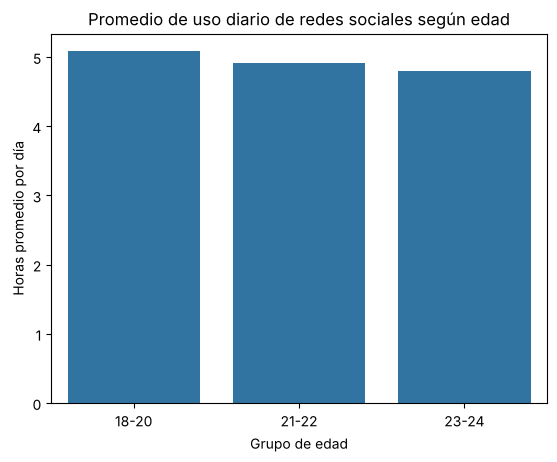

In [20]:
# Promedio de horas diarias de uso por grupo de edad
uso_edad = (
    df.groupby("Grupo_Edad", observed=True)["Avg_Daily_Usage_Hours"]
      .mean()
      .reset_index()
)

sns.barplot(
    data=uso_edad,
    x="Grupo_Edad",
    y="Avg_Daily_Usage_Hours"
)

plt.title("Promedio de uso diario de redes sociales según edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Horas promedio por día")
plt.show()

#### Gráfico 1.2 · Salud mental según grupo de edad

Se compara el **puntaje promedio de salud mental** entre los grupos de edad. Considerando que un valor más alto representa una mejor salud mental, el gráfico permite identificar qué grupos presentan resultados relativamente más favorables o desfavorables.

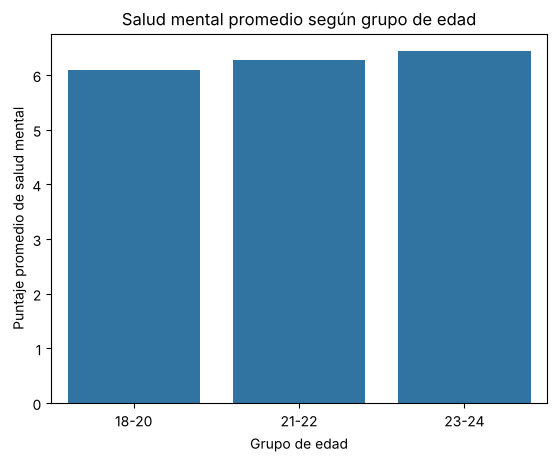

In [21]:
# Puntaje promedio de salud mental por grupo de edad
salud_edad = (
    df.groupby("Grupo_Edad", observed=True)["Mental_Health_Score"]
      .mean()
      .reset_index()
)

sns.barplot(
    data=salud_edad,
    x="Grupo_Edad",
    y="Mental_Health_Score"
)

plt.title("Salud mental promedio según grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Puntaje promedio de salud mental")
plt.show()

#### Gráfico 1.3 · Impacto académico percibido según grupo de edad

Se comparan las **proporciones de estudiantes que indican si las redes sociales afectan o no su desempeño académico**. Se utiliza un gráfico de barras apiladas porque `Affects_Academic_Performance` es una variable categórica; al trabajar con porcentajes, la comparación no depende del tamaño de cada grupo.

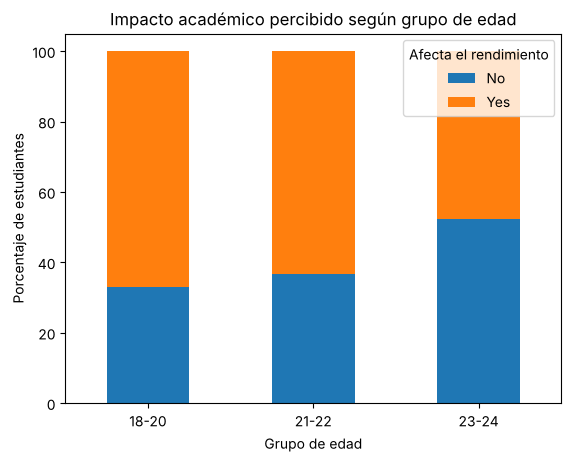

In [22]:
# Barras apiladas a partir de la tabla de porcentajes impacto_edad (sección 4.2)
impacto_edad.plot(
    kind="bar",
    stacked=True
)

plt.title("Impacto académico percibido según grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Porcentaje de estudiantes")
plt.legend(title="Afecta el rendimiento")
plt.xticks(rotation=0)
plt.show()

#### Gráfico 1.4 · Distribución del uso diario según grupo de edad

El diagrama de caja (*boxplot*) permite observar no solo la tendencia central, sino también la **dispersión de los datos y la presencia de posibles valores extremos**, lo que brinda una visión más completa de las diferencias entre los grupos.

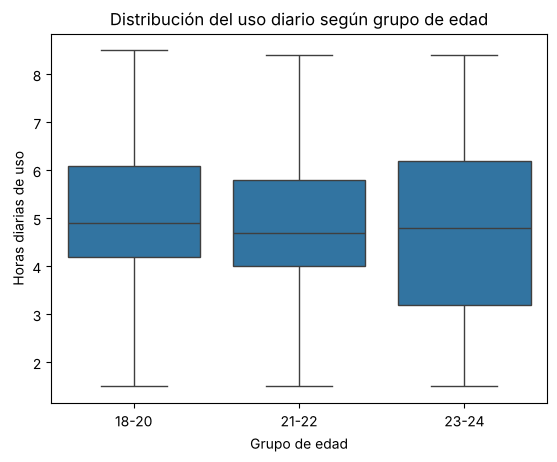

In [23]:
# Distribución completa de las horas de uso dentro de cada grupo de edad
sns.boxplot(
    data=df,
    x="Grupo_Edad",
    y="Avg_Daily_Usage_Hours"
)

plt.title("Distribución del uso diario según grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Horas diarias de uso")
plt.show()

<a id="5-pregunta-2-impacto-segun-el-nivel-de-desarrollo-del-pais"></a>
# 5 | Pregunta 2 · Impacto según el nivel de desarrollo del país

### ¿Cuál es la pregunta?

**¿Existen diferencias en el impacto de las redes sociales sobre los estudiantes según el nivel de desarrollo del país en el que viven?**

### ¿Por qué vale la pena responderla?

El contexto socioeconómico del país puede influir en el acceso a la tecnología, los hábitos digitales y las consecuencias asociadas al uso de redes sociales. Analizar estas diferencias permite comprender si el impacto de las redes está condicionado por el entorno en el que vive el estudiante.

### ¿Qué respuesta encontramos?

Los estudiantes de **países en desarrollo** presentan un **mayor promedio de horas diarias de uso** y un **puntaje promedio de salud mental más bajo** que los de países desarrollados, es decir, un perfil relativamente menos favorable dentro de la muestra.

In [24]:
# Punto de partida: copia de la base común
df = df_base.copy()

### 5.1 | Clasificación de países según nivel de desarrollo

Para comparar países se crea una nueva variable denominada `Nivel_Desarrollo`, que agrupa los países del dataset en categorías según su nivel de desarrollo. Primero se relevan los países presentes en los datos.

In [25]:
# Cantidad de estudiantes por país (se imprime completo, sin que pandas oculte filas)
paises = df["Country"].value_counts()

print(paises.to_string())

Country
India              192
USA                155
Canada             112
UK                  88
Australia           80
Germany             60
Spain               54
Mexico              54
France              54
Switzerland         54
Turkey              54
Ireland             54
Denmark             54
Japan               42
Russia              42
Italy               42
Bangladesh          40
Nepal               38
Pakistan            38
Maldives            38
Sri Lanka           38
China               32
Poland              32
South Korea         26
UAE                 16
Singapore           16
New Zealand         16
Brazil              16
Malaysia            16
Netherlands         16
Finland             16
Austria              2
Thailand             2
Philippines          2
Taiwan               2
Indonesia            2
Hong Kong            2
Israel               2
Egypt                2
Morocco              2
Vietnam              2
Belgium              2
Greece               2
Por

In [26]:
# Lista ordenada de países únicos del dataset
paises_unicos = sorted(df["Country"].dropna().unique())

print(paises_unicos)
print("Cantidad de países:", len(paises_unicos))

['Afghanistan', 'Albania', 'Andorra', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahamas', 'Bahrain', 'Bangladesh', 'Belarus', 'Belgium', 'Bhutan', 'Bolivia', 'Bosnia', 'Brazil', 'Bulgaria', 'Canada', 'Chile', 'China', 'Colombia', 'Costa Rica', 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Ecuador', 'Egypt', 'Estonia', 'Finland', 'France', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Hong Kong', 'Hungary', 'Iceland', 'India', 'Indonesia', 'Iraq', 'Ireland', 'Israel', 'Italy', 'Jamaica', 'Japan', 'Jordan', 'Kazakhstan', 'Kenya', 'Kosovo', 'Kuwait', 'Kyrgyzstan', 'Latvia', 'Lebanon', 'Liechtenstein', 'Lithuania', 'Luxembourg', 'Malaysia', 'Maldives', 'Malta', 'Mexico', 'Moldova', 'Monaco', 'Montenegro', 'Morocco', 'Nepal', 'Netherlands', 'New Zealand', 'Nigeria', 'North Macedonia', 'Norway', 'Oman', 'Pakistan', 'Panama', 'Paraguay', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Qatar', 'Romania', 'Russia', 'San Marino', 'Serbia', 'Singapore', 'Slovakia', 'Slovenia',

#### Criterio de clasificación

Se utilizó como referencia la **clasificación por nivel de ingreso del Banco Mundial**, una fuente internacional estandarizada y actualizada periódicamente que permite comparar economías bajo un mismo criterio.

El Banco Mundial divide a las economías en cuatro grupos según su **Ingreso Nacional Bruto (GNI) per cápita**: ingreso bajo, medio-bajo, medio-alto y alto. Para simplificar el análisis, las economías de **ingreso alto** se agrupan como **"Desarrollado"** y las restantes como **"En desarrollo"**.

Este criterio permite construir una clasificación reproducible y menos subjetiva que una asignación manual país por país. De todos modos, el nivel de ingreso no representa por sí solo todas las dimensiones del desarrollo económico y social, por lo que esta simplificación constituye una **limitación del análisis**.

In [27]:
# Clasificamos los países según el nivel de ingreso del Banco Mundial.
# "Desarrollado" = economías de ingreso alto
# "En desarrollo" = economías de ingreso bajo, medio-bajo o medio-alto

clasificacion_paises = {

    # Desarrollados
    "Andorra": "Desarrollado",
    "Australia": "Desarrollado",
    "Austria": "Desarrollado",
    "Bahamas": "Desarrollado",
    "Bahrain": "Desarrollado",
    "Belgium": "Desarrollado",
    "Bulgaria": "Desarrollado",
    "Canada": "Desarrollado",
    "Chile": "Desarrollado",
    "Costa Rica": "Desarrollado",
    "Croatia": "Desarrollado",
    "Cyprus": "Desarrollado",
    "Czech Republic": "Desarrollado",
    "Denmark": "Desarrollado",
    "Estonia": "Desarrollado",
    "Finland": "Desarrollado",
    "France": "Desarrollado",
    "Germany": "Desarrollado",
    "Greece": "Desarrollado",
    "Hong Kong": "Desarrollado",
    "Hungary": "Desarrollado",
    "Iceland": "Desarrollado",
    "Ireland": "Desarrollado",
    "Israel": "Desarrollado",
    "Italy": "Desarrollado",
    "Japan": "Desarrollado",
    "Kuwait": "Desarrollado",
    "Latvia": "Desarrollado",
    "Liechtenstein": "Desarrollado",
    "Lithuania": "Desarrollado",
    "Luxembourg": "Desarrollado",
    "Malta": "Desarrollado",
    "Monaco": "Desarrollado",
    "Netherlands": "Desarrollado",
    "New Zealand": "Desarrollado",
    "Norway": "Desarrollado",
    "Oman": "Desarrollado",
    "Panama": "Desarrollado",
    "Poland": "Desarrollado",
    "Portugal": "Desarrollado",
    "Qatar": "Desarrollado",
    "Romania": "Desarrollado",
    "Russia": "Desarrollado",
    "San Marino": "Desarrollado",
    "Singapore": "Desarrollado",
    "Slovakia": "Desarrollado",
    "Slovenia": "Desarrollado",
    "South Korea": "Desarrollado",
    "Spain": "Desarrollado",
    "Sweden": "Desarrollado",
    "Switzerland": "Desarrollado",
    "Taiwan": "Desarrollado",
    "Trinidad": "Desarrollado",
    "UAE": "Desarrollado",
    "UK": "Desarrollado",
    "USA": "Desarrollado",
    "Uruguay": "Desarrollado",

    # En desarrollo
    "Afghanistan": "En desarrollo",
    "Albania": "En desarrollo",
    "Argentina": "En desarrollo",
    "Armenia": "En desarrollo",
    "Azerbaijan": "En desarrollo",
    "Bangladesh": "En desarrollo",
    "Belarus": "En desarrollo",
    "Bhutan": "En desarrollo",
    "Bolivia": "En desarrollo",
    "Bosnia": "En desarrollo",
    "Brazil": "En desarrollo",
    "China": "En desarrollo",
    "Colombia": "En desarrollo",
    "Ecuador": "En desarrollo",
    "Egypt": "En desarrollo",
    "Georgia": "En desarrollo",
    "Ghana": "En desarrollo",
    "India": "En desarrollo",
    "Indonesia": "En desarrollo",
    "Iraq": "En desarrollo",
    "Jamaica": "En desarrollo",
    "Jordan": "En desarrollo",
    "Kazakhstan": "En desarrollo",
    "Kenya": "En desarrollo",
    "Kosovo": "En desarrollo",
    "Kyrgyzstan": "En desarrollo",
    "Lebanon": "En desarrollo",
    "Malaysia": "En desarrollo",
    "Maldives": "En desarrollo",
    "Mexico": "En desarrollo",
    "Moldova": "En desarrollo",
    "Montenegro": "En desarrollo",
    "Morocco": "En desarrollo",
    "Nepal": "En desarrollo",
    "Nigeria": "En desarrollo",
    "North Macedonia": "En desarrollo",
    "Pakistan": "En desarrollo",
    "Paraguay": "En desarrollo",
    "Peru": "En desarrollo",
    "Philippines": "En desarrollo",
    "Serbia": "En desarrollo",
    "South Africa": "En desarrollo",
    "Sri Lanka": "En desarrollo",
    "Syria": "En desarrollo",
    "Tajikistan": "En desarrollo",
    "Thailand": "En desarrollo",
    "Turkey": "En desarrollo",
    "Ukraine": "En desarrollo",
    "Uzbekistan": "En desarrollo",
    "Venezuela": "En desarrollo",
    "Vietnam": "En desarrollo",
    "Yemen": "En desarrollo"
}

In [28]:
# Creamos la variable Nivel_Desarrollo a partir de la clasificación definida
df["Nivel_Desarrollo"] = df["Country"].map(clasificacion_paises)

# Países que no pudieron ser clasificados
df[df["Nivel_Desarrollo"].isna()]["Country"].unique()

array(['Vatican City'], dtype=object)

**Caso especial: Vatican City.** El Banco Mundial no lo incluye en su clasificación por ingreso, por lo que no se lo asigna arbitrariamente a ninguno de los dos grupos: queda como faltante en `Nivel_Desarrollo` y se excluye únicamente de las comparaciones que utilizan esta variable.

In [29]:
# Cantidad de estudiantes en cada grupo (incluye los no clasificados)
df["Nivel_Desarrollo"].value_counts(dropna=False)

Nivel_Desarrollo
Desarrollado     1103
En desarrollo     638
NaN                 2
Name: count, dtype: int64

**Interpretación:** la clasificación permitió agrupar a la mayoría de los estudiantes en dos categorías: **1.103 estudiantes de países desarrollados** y **638 de países en desarrollo**. Quedaron **2 observaciones sin clasificar** (Vatican City).

La distribución no es equilibrada, ya que el grupo de países desarrollados tiene más observaciones. Esta diferencia debe tenerse en cuenta al interpretar los resultados.

### 5.2 | Resumen estadístico por nivel de desarrollo

Se calculan la **media** y la **mediana** de los principales indicadores y la proporción de estudiantes que perciben un impacto académico, para cada nivel de desarrollo.

In [30]:
# Media y mediana de los principales indicadores según nivel de desarrollo
resumen_desarrollo = df.groupby("Nivel_Desarrollo")[
    ["Avg_Daily_Usage_Hours",
     "Sleep_Hours_Per_Night",
     "Mental_Health_Score"]
].agg(["mean", "median"]).round(2)

resumen_desarrollo

Avg_Daily_Usage_Hours        Sleep_Hours_Per_Night         \
                                  mean median                  mean median   
Nivel_Desarrollo                                                             
Desarrollado                      4.83    4.6                  6.97    7.1   
En desarrollo                     5.25    5.2                  6.45    6.3   

                 Mental_Health_Score         
                                mean median  
Nivel_Desarrollo                             
Desarrollado                    6.37    6.3  
En desarrollo                   5.94    6.0

In [31]:
# Porcentaje de respuestas sobre impacto académico según nivel de desarrollo
impacto_desarrollo = pd.crosstab(
    df["Nivel_Desarrollo"],
    df["Affects_Academic_Performance"],
    normalize="index"
) * 100

impacto_desarrollo

Affects_Academic_Performance,No,Yes
Nivel_Desarrollo,,
Desarrollado,43.517679,56.482321
En desarrollo,25.548589,74.451411


**Interpretación:** los resultados descriptivos sugieren que los estudiantes de **países en desarrollo** muestran resultados menos favorables en varios indicadores en comparación con los de países desarrollados. Estas diferencias se observan dentro de la muestra y no permiten establecer relaciones causales.

### 5.3 | Visualización de resultados

#### Gráfico 2.1 · Uso diario de redes sociales según nivel de desarrollo

Se compara el **promedio de horas diarias de uso** entre estudiantes de países desarrollados y en desarrollo, para analizar si el nivel de desarrollo está asociado con diferencias en la intensidad de uso.

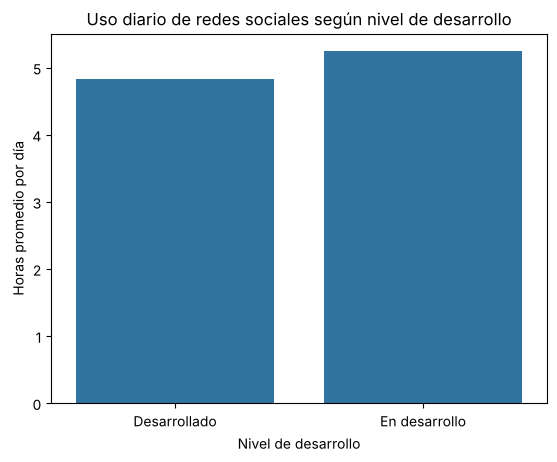

In [32]:
# Promedio de uso diario según nivel de desarrollo
uso_desarrollo = (
    df.groupby("Nivel_Desarrollo")["Avg_Daily_Usage_Hours"]
      .mean()
      .reset_index()
)

sns.barplot(
    data=uso_desarrollo,
    x="Nivel_Desarrollo",
    y="Avg_Daily_Usage_Hours"
)

plt.title("Uso diario de redes sociales según nivel de desarrollo")
plt.xlabel("Nivel de desarrollo")
plt.ylabel("Horas promedio por día")
plt.show()

**Interpretación:** los estudiantes de **países en desarrollo presentan un mayor promedio de uso diario**, lo que indica una mayor exposición a las redes sociales dentro de la muestra. Este resultado aporta evidencia descriptiva de una diferencia entre ambos grupos, aunque no permite afirmar que el nivel de desarrollo sea la causa del mayor uso.

#### Gráfico 2.2 · Salud mental según nivel de desarrollo

Se compara el **puntaje promedio de salud mental** entre ambos grupos de países. Dado que los valores más altos indican mejor salud mental, la comparación permite observar si alguno de los grupos presenta indicadores de bienestar menos favorables.

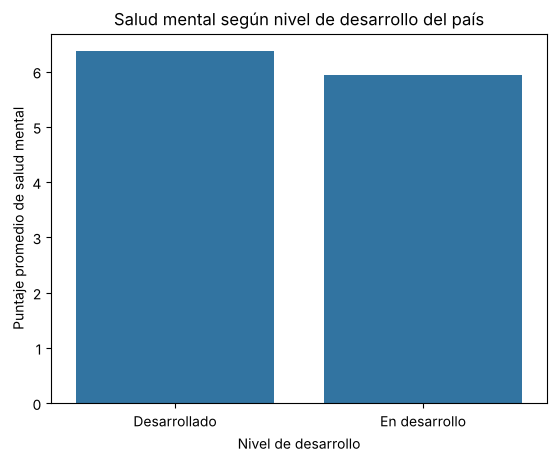

In [33]:
# Puntaje promedio de salud mental según nivel de desarrollo
salud_desarrollo = (
    df.groupby("Nivel_Desarrollo")["Mental_Health_Score"]
      .mean()
      .reset_index()
)

sns.barplot(
    data=salud_desarrollo,
    x="Nivel_Desarrollo",
    y="Mental_Health_Score"
)

plt.title("Salud mental según nivel de desarrollo del país")
plt.xlabel("Nivel de desarrollo")
plt.ylabel("Puntaje promedio de salud mental")
plt.show()

**Interpretación:** los estudiantes de **países en desarrollo presentan un puntaje promedio de salud mental menor** que los de países desarrollados, lo que sugiere un indicador de bienestar mental relativamente menos favorable dentro de la muestra. Se trata de una asociación descriptiva, no de una relación causal.

#### Gráfico 2.3 · Distribución de las horas de sueño según nivel de desarrollo

Se utiliza un *boxplot* para comparar la mediana, la dispersión y los posibles valores extremos de las **horas de sueño por noche** en ambos grupos, y así observar si existen diferencias en los patrones de descanso.

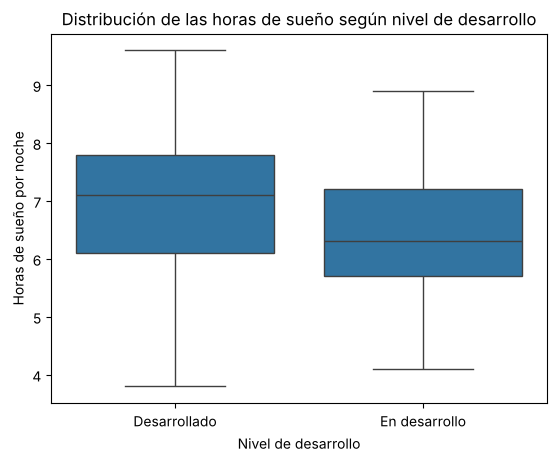

In [34]:
# Distribución de las horas de sueño según nivel de desarrollo
sns.boxplot(
    data=df,
    x="Nivel_Desarrollo",
    y="Sleep_Hours_Per_Night"
)

plt.title("Distribución de las horas de sueño según nivel de desarrollo")
plt.xlabel("Nivel de desarrollo")
plt.ylabel("Horas de sueño por noche")
plt.show()

**Interpretación:** la posición de las medianas permite identificar qué grupo presenta, en términos generales, una menor cantidad de horas de descanso, mientras que el tamaño de las cajas muestra la variabilidad dentro de cada grupo. En línea con la tabla de la sección 5.2, los estudiantes de **países en desarrollo duermen menos** (mediana de 6,3 h frente a 7,1 h en países desarrollados).

### 5.4 | Conclusión de la pregunta 2

Se observan diferencias entre estudiantes de **países desarrollados** y **en desarrollo** en varios indicadores vinculados al uso e impacto de las redes sociales. Los estudiantes de países en desarrollo presentan **más horas diarias de uso**, **menos horas de sueño** y **un puntaje promedio de salud mental más bajo**, lo que configura un perfil relativamente menos favorable dentro de la muestra.

Estos resultados deben interpretarse con cautela: la clasificación se construyó a partir del nivel de ingreso del Banco Mundial, que simplifica un concepto multidimensional como el desarrollo, y el análisis es descriptivo, por lo que identifica asociaciones pero no permite afirmar que el nivel de desarrollo sea la causa directa de los resultados.

<a id="6-preguntas-3-y-4-sueno-y-rendimiento-academico"></a>
# 6 | Preguntas 3 y 4 · Sueño y rendimiento académico

### ¿Cuáles son las preguntas?

- **Pregunta 3:** ¿el uso de redes sociales repercute en las horas de sueño?
- **Pregunta 4:** ¿hay un impacto en el rendimiento académico asociado al uso de redes sociales? ¿Ese impacto se vincula con la falta de sueño?

### ¿Por qué vale la pena responderlas?

Se cree comúnmente que el uso de pantallas durante períodos prolongados repercute negativamente en el sueño, y el descanso es un factor clave del desempeño académico. Analizar ambas variables en conjunto permite evaluar si el uso de redes, el sueño y el rendimiento se mueven juntos.

### ¿Qué respuesta encontramos?

Existe una **relación negativa clara** entre el uso de redes y las horas de sueño. Además, quienes declaran que su desempeño académico se ve afectado concentran **más horas de uso y menos horas de sueño** que quienes no se ven afectados.

In [35]:
# Punto de partida: copia de la base común
df = df_base.copy()

### 6.1 | Pregunta 3 · Uso de redes sociales y horas de sueño

Se grafica cada estudiante como un punto (uso diario vs. horas de sueño) y se ajusta una **recta de regresión lineal** con `np.polyfit` para resumir la tendencia.

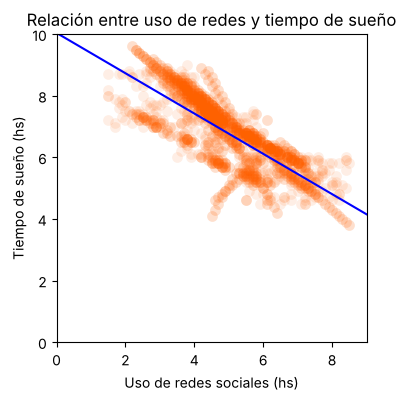

In [36]:
# Ajuste lineal: Sleep = m * Usage + b
m, b = np.polyfit(df["Avg_Daily_Usage_Hours"], df["Sleep_Hours_Per_Night"], 1)


def f(x):
    # Recta de regresión estimada
    return (x * m) + b


recorrido = np.linspace(0, 9, 100)   # valores de uso para dibujar la recta

# Diagrama de dispersión con la recta de tendencia
plt.figure(figsize=(4, 4))

plt.scatter(
    df["Avg_Daily_Usage_Hours"],
    df["Sleep_Hours_Per_Night"],
    s=60, c="#FE6100", alpha=0.1, lw=0,
)
plt.plot(recorrido, f(recorrido), color="blue")

plt.xlim((0, 9))
plt.ylim((0, 10))
plt.xlabel("Uso de redes sociales (hs)")
plt.ylabel("Tiempo de sueño (hs)")
plt.title("Relación entre uso de redes y tiempo de sueño")
plt.show()

In [37]:
# Soporte cuantitativo del gráfico anterior
correlacion_uso_sueno = df["Avg_Daily_Usage_Hours"].corr(df["Sleep_Hours_Per_Night"])

print(f"Pendiente de la recta (m): {m:.2f} horas de sueño por cada hora de uso")
print(f"Ordenada al origen (b)  : {b:.2f}")
print(f"Correlación uso-sueño   : {correlacion_uso_sueno:.2f}")

Pendiente de la recta (m): -0.65 horas de sueño por cada hora de uso
Ordenada al origen (b)  : 10.04
Correlación uso-sueño   : -0.79


**Interpretación:** se observa una **clara relación negativa** entre el incremento del tiempo de uso de redes sociales y las horas de sueño: la nube de puntos desciende de izquierda a derecha y la recta estimada indica que, en promedio, cada hora adicional de uso se asocia con aproximadamente **0,65 horas menos de sueño** (correlación de -0,79). Se trata de una asociación; no prueba por sí sola que el uso de redes cause la reducción del descanso.

### 6.2 | Pregunta 4 · Impacto en el rendimiento académico

Se separa a los estudiantes según su respuesta en `Affects_Academic_Performance` y se repite el diagrama de dispersión diferenciando ambos grupos por color, para ver si el impacto académico se concentra en quienes usan más las redes y duermen menos.

In [38]:
# Segmentación de estudiantes según impacto académico percibido
afectados = df.loc[df["Affects_Academic_Performance"] == "Yes"]
no_afectados = df.loc[df["Affects_Academic_Performance"] == "No"]

print("Estudiantes con desempeño afectado   :", len(afectados))
print("Estudiantes con desempeño no afectado:", len(no_afectados))

Estudiantes con desempeño afectado   : 1100
Estudiantes con desempeño no afectado: 643


#### Gráfico 4.1 · Uso de redes y sueño según desempeño académico

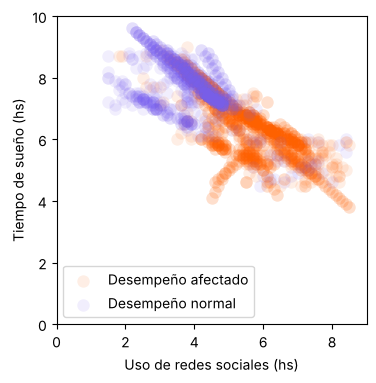

In [39]:
# Dispersión superpuesta: ambos grupos en el mismo gráfico
plt.figure(figsize=(4, 4))

plt.scatter(
    afectados["Avg_Daily_Usage_Hours"],
    afectados["Sleep_Hours_Per_Night"],
    s=80, c="#FE6100", alpha=0.1, lw=0, label="Desempeño afectado")
plt.scatter(
    no_afectados["Avg_Daily_Usage_Hours"],
    no_afectados["Sleep_Hours_Per_Night"],
    s=80, c="#785EF0", alpha=0.1, lw=0, label="Desempeño normal")

plt.xlim((0, 9))
plt.ylim((0, 10))
plt.xlabel("Uso de redes sociales (hs)")
plt.ylabel("Tiempo de sueño (hs)")
plt.legend()
plt.show()

#### Gráfico 4.2 · Comparación lado a lado de ambos grupos

Para evitar la superposición de puntos, se grafica cada grupo en un panel separado con los mismos ejes.

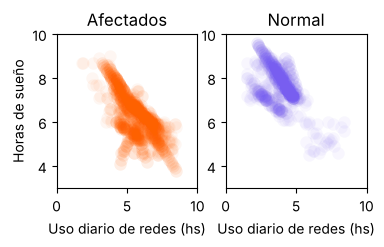

In [40]:
# Paneles separados: afectados (izquierda) y no afectados (derecha)
fig, ax = plt.subplots(1, 2, figsize=(4, 2))

ax[0].scatter(
    afectados["Avg_Daily_Usage_Hours"],
    afectados["Sleep_Hours_Per_Night"],
    s=80, c="#FE6100", alpha=0.05, lw=0, label="Mal desempeño")

ax[0].set_title("Afectados")
ax[0].set_xlabel("Uso diario de redes (hs)")
ax[0].set_xlim((0, 10))
ax[0].set_ylabel("Horas de sueño")
ax[0].set_ylim((3, 10))

ax[1].scatter(
    no_afectados["Avg_Daily_Usage_Hours"],
    no_afectados["Sleep_Hours_Per_Night"],
    s=80, c="#785EF0", alpha=0.05, lw=0, label="Normal")

ax[1].set_title("Normal")
ax[1].set_xlabel("Uso diario de redes (hs)")
ax[1].set_xlim((0, 10))
ax[1].set_ylim((3, 10))

plt.show()

**Interpretación:** quienes declaran que su desempeño académico se vio perjudicado se ubican mayoritariamente en la zona de **más horas de uso y menos horas de sueño**, mientras que quienes no se ven afectados se concentran en la zona opuesta.

#### Gráfico 4.3 · Distribución de uso y sueño según desempeño académico

Los *boxplots* resumen la mediana y la dispersión de ambas variables en cada grupo.

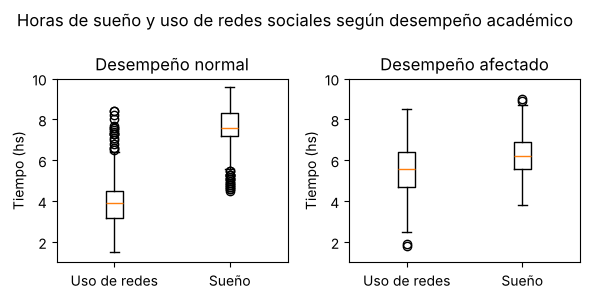

In [41]:
# Boxplots de uso de redes y sueño, por grupo de desempeño
fig, ax = plt.subplots(1, 2, figsize=(6, 3))

ax[0].boxplot(
    [
        no_afectados["Avg_Daily_Usage_Hours"],
        no_afectados["Sleep_Hours_Per_Night"]
    ],
    tick_labels=["Uso de redes", "Sueño"]
)
ax[1].boxplot(
    [
        afectados["Avg_Daily_Usage_Hours"],
        afectados["Sleep_Hours_Per_Night"]
    ],
    tick_labels=["Uso de redes", "Sueño"]
)

ax[0].set_title("Desempeño normal")
ax[0].set_ylabel("Tiempo (hs)")
ax[0].set_ylim((1, 10))

ax[1].set_title("Desempeño afectado")
ax[1].set_ylabel("Tiempo (hs)")
ax[1].set_ylim((1, 10))

fig.suptitle("Horas de sueño y uso de redes sociales según desempeño académico")
plt.tight_layout()
plt.show()

In [42]:
# Soporte cuantitativo: mediana de uso y sueño en cada grupo
resumen_desempeno = pd.DataFrame({
    "Desempeño normal": no_afectados[["Avg_Daily_Usage_Hours", "Sleep_Hours_Per_Night"]].median(),
    "Desempeño afectado": afectados[["Avg_Daily_Usage_Hours", "Sleep_Hours_Per_Night"]].median(),
}).round(2)

resumen_desempeno

,Desempeño normal,Desempeño afectado
Avg_Daily_Usage_Hours,3.9,5.6
Sleep_Hours_Per_Night,7.6,6.2


**Interpretación:** aquellos cuyo desempeño académico se vio perjudicado tienen **menos horas de sueño y mayor uso de redes sociales** (medianas de 5,6 h de uso y 6,2 h de sueño, frente a 3,9 h y 7,6 h en quienes no se ven afectados).

En conjunto con la pregunta 3, los resultados son consistentes con la hipótesis de que el impacto académico podría estar mediado, al menos en parte, por la **falta de sueño**. Sin embargo, al tratarse de un análisis descriptivo, no es posible separar el efecto del uso de redes del efecto del sueño ni establecer causalidad.

<a id="7-preguntas-5-y-6-plataformas-y-brecha-de-genero"></a>
# 7 | Preguntas 5 y 6 · Plataformas y brecha de género

### a) ¿Cuál es la pregunta?

**¿Hay redes sociales que impactan más que otras sobre los estudiantes y existe una brecha de género en ese impacto?**

El impacto se mide a partir de: horas de uso diario (`Avg_Daily_Usage_Hours`), horas de sueño (`Sleep_Hours_Per_Night`), salud mental (`Mental_Health_Score`, más alto = mejor) y percepción de afectación académica (`Affects_Academic_Performance`).

### b) ¿Por qué vale la pena responderla?

Hablar de "redes sociales" en general esconde que no todas se usan igual y que pueden tener efectos muy distintos. Identificar cuáles se asocian con peor bienestar, salud mental o calidad de vida permite sacar conclusiones más ricas y brindar recomendaciones más específicas. Además, permite identificar si existe una brecha de género en ese impacto.

### c) ¿Qué respuesta encontramos?

**1. ¿Hay redes que impactan más que otras? Sí.** Los estudiantes que usan principalmente **WhatsApp, TikTok y Snapchat** pasan más horas en las redes, duermen menos, tienen peor salud mental y más afectación académica (en WhatsApp, el 100 % dice que las redes afectan su rendimiento). Los que usan **LinkedIn, Twitter y Facebook** tienen los resultados más favorables. Sin embargo, gran parte de esta diferencia se debe a las **horas de uso**: al comparar estudiantes con una cantidad de horas parecida, las diferencias entre plataformas se achican bastante, aunque no desaparecen.

**2. ¿Hay brecha de género? Muy leve, no significativa.** Mujeres y varones tienen resultados muy parecidos en horas de uso, sueño, salud mental y afectación académica. En salud mental la diferencia es de solo 0,10 puntos (6,15 las mujeres y 6,25 los varones), y dentro de cada plataforma las diferencias también son chicas. Donde sí aparece una diferencia mayor es en **qué plataforma** se usa: Instagram la usan más mujeres, y Facebook y WhatsApp, más varones.

### 7.1 | Transformaciones específicas

Esta sección parte de la base común (que ya no incluye `Relationship_Status`, ver sección 3.1) y aplica cuatro transformaciones adicionales.

In [43]:
# Punto de partida: copia de la base común
df = df_base.copy()
print(df.columns.tolist())

['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Country', 'Avg_Daily_Usage_Hours', 'Most_Used_Platform', 'Affects_Academic_Performance', 'Sleep_Hours_Per_Night', 'Mental_Health_Score']


**Transformación 1: eliminar filas duplicadas.** Como se comprobó en la sección 2.4, una fila que aparece dos veces es el mismo estudiante cargado dos veces. Con `drop_duplicates()` se deja **una sola copia** de cada fila idéntica.

In [44]:
n_inicial = len(df)

# Si dos filas son idénticas en todas las columnas, es el mismo estudiante cargado dos veces: dejamos una sola
df = df.drop_duplicates().reset_index(drop=True)

print("Filas antes     :", n_inicial)
print("Filas eliminadas:", n_inicial - len(df))
print("Filas ahora     :", len(df))
print("Filas duplicadas que quedan:", df.duplicated().sum())

Filas antes     : 1743
Filas eliminadas: 705
Filas ahora     : 1038
Filas duplicadas que quedan: 0


Quedan **1.038 filas (estudiantes)**.

Algunos `Student_ID` siguen apareciendo más de una vez, pero esas filas **no son duplicados**: corresponden a estudiantes distintos (otro género, otro país, otra edad) que comparten el mismo número. Se verifica con el ID 1 como ejemplo.

In [45]:
print("Student_ID que todavía se repiten:", df["Student_ID"].duplicated().sum())

# Dos personas distintas con el mismo ID: no se eliminan
df[df["Student_ID"] == 1]

Student_ID que todavía se repiten: 237


,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score
319,1,22,Male,High School,USA,4.0,Twitter,No,7.6,8.6
333,1,19,Female,Undergraduate,Bangladesh,5.2,Instagram,Yes,6.5,6.0


Como las filas del ID 1 difieren en género, edad, país y plataforma, son estudiantes distintos y se conservan. Borrarlas por compartir el ID habría eliminado a personas reales del análisis.

**Transformación 2: agrupar plataformas con pocas observaciones.** WeChat, LINE, KakaoTalk y VKontakte tienen entre 12 y 15 casos cada una; con tan pocos datos sus promedios son inestables. Por eso se agrupan en una categoría **"Otras"**, y las 8 plataformas restantes (con más de 50 casos cada una) se mantienen separadas.

In [46]:
# 1) Cantidad de estudiantes por plataforma
conteo = df["Most_Used_Platform"].value_counts()

# 2) Plataformas con menos de 20 estudiantes: son las que se agrupan en "Otras"
minoritarias = conteo[conteo < 20].index.tolist()
print("Plataformas con menos de 20 estudiantes (se agrupan en 'Otras'):", minoritarias)

# 3) Nueva columna: esas plataformas pasan a llamarse "Otras"
df["Plataforma"] = df["Most_Used_Platform"].replace({"WeChat": "Otras", "LINE": "Otras", "KakaoTalk": "Otras", "VKontakte": "Otras"})

# 4) Verificamos el resultado
df["Plataforma"].value_counts()

Plataformas con menos de 20 estudiantes (se agrupan en 'Otras'): ['WeChat', 'LINE', 'VKontakte', 'KakaoTalk']


Plataforma
Instagram    301
TikTok       196
Facebook     172
Twitter       73
LinkedIn      66
YouTube       65
Snapchat      60
WhatsApp      54
Otras         51
Name: count, dtype: int64

**Transformación 3: impacto académico numérico.** `Affects_Academic_Performance` toma los valores "Yes"/"No". Se crea `Afecta_Rendimiento` (1 = Sí, 0 = No) para poder operar sobre la columna.

Como la columna solo tiene unos y ceros, **su promedio es la proporción de estudiantes que dicen que las redes afectan su rendimiento** (por ejemplo, 0,75 = 75 % respondió "Yes"; lo que falta para llegar a 1 es la proporción de "No").

In [47]:
# 1 si el estudiante responde "Yes", 0 si responde "No"
df["Afecta_Rendimiento"] = (df["Affects_Academic_Performance"] == "Yes").astype(int)

# Verificación de la correspondencia entre ambas columnas
df[["Affects_Academic_Performance", "Afecta_Rendimiento"]].value_counts()

Affects_Academic_Performance  Afecta_Rendimiento
Yes                           1                     647
No                            0                     391
Name: count, dtype: int64

**Transformación 4: nivel de uso diario.** Con `pd.cut` se clasifica el uso en tres niveles (**Bajo**: hasta 4 h, **Medio**: entre 4 y 6 h, **Alto**: más de 6 h). Esto permite comparar plataformas entre estudiantes con una cantidad de horas de uso parecida y así distinguir si las diferencias se deben a la plataforma o solo a las horas de uso.

In [48]:
# Clasificación del uso diario en tres niveles
df["Nivel_Uso"] = pd.cut(df["Avg_Daily_Usage_Hours"],
                         bins=[0, 4, 6, 10],
                         labels=["Bajo (≤4 h)", "Medio (4-6 h)", "Alto (>6 h)"])

df["Nivel_Uso"].value_counts().sort_index()

Nivel_Uso
Bajo (≤4 h)      278
Medio (4-6 h)    493
Alto (>6 h)      267
Name: count, dtype: int64

El nivel **Medio** es el más numeroso: 493 estudiantes usan las redes entre 4 y 6 horas por día. Le siguen el nivel **Bajo** (278) y el **Alto** (267), con una cantidad parecida de estudiantes.

### 7.2 | Resumen estadístico por grupo

**Agrupación 1: por plataforma.** Con `groupby` y `agg` se calcula la media de cada indicador y la cantidad de estudiantes, ordenando de peor a mejor salud mental.

In [49]:
# Indicadores promedio por plataforma, ordenados de peor a mejor salud mental
por_plataforma = df.groupby("Plataforma").agg(
    uso_horas=("Avg_Daily_Usage_Hours", "mean"),
    sueno_horas=("Sleep_Hours_Per_Night", "mean"),
    salud_mental=("Mental_Health_Score", "mean"),
    afecta_rendimiento=("Afecta_Rendimiento", "mean"),     # proporción de estudiantes afectados
    estudiantes=("Student_ID", "count"),
).sort_values("salud_mental")

display(por_plataforma.round(2))

,uso_horas,sueno_horas,salud_mental,afecta_rendimiento,estudiantes
Plataforma,,,,,
WhatsApp,6.48,5.87,5.54,1.00,54
TikTok,5.38,6.32,5.77,0.85,196
Snapchat,5.54,6.01,5.81,0.77,60
Instagram,4.88,6.96,6.15,0.65,301
YouTube,4.91,6.51,6.34,0.52,65
Facebook,4.83,7.08,6.51,0.41,172
Twitter,4.89,6.67,6.57,0.51,73
LinkedIn,4.23,6.82,6.77,0.33,66
Otras,4.34,7.61,6.84,0.39,51


**Interpretación:** se observan grandes diferencias entre plataformas. **WhatsApp** muestra los resultados más preocupantes: más horas de uso (6,5 h), menos sueño (5,9 h), la peor salud mental (5,54) y el 100 % de sus estudiantes declara que las redes los afectan académicamente. Le siguen **TikTok** (salud mental de 5,77) y **Snapchat** (5,81).

En el otro extremo, el grupo **"Otras"** (6,84), **LinkedIn** (6,77), **Twitter** (6,57) y **Facebook** (6,51) muestran mejor salud mental, además de más sueño y menor afectación académica. **Instagram**, la más usada, queda en una posición intermedia (6,15).

**Agrupación 2: por género.** Misma tabla, agregando la **mediana** de salud mental además de la media, para evaluar si hay brecha de género.

In [50]:
# Indicadores promedio por género (incluye la mediana de salud mental)
por_genero = df.groupby("Gender").agg(
    uso_horas=("Avg_Daily_Usage_Hours", "mean"),
    sueno_horas=("Sleep_Hours_Per_Night", "mean"),
    salud_mental=("Mental_Health_Score", "mean"),
    salud_mental_mediana=("Mental_Health_Score", "median"),
    afecta_rendimiento=("Afecta_Rendimiento", "mean"),
    estudiantes=("Student_ID", "count"),
)

display(por_genero.round(2))

,uso_horas,sueno_horas,salud_mental,salud_mental_mediana,afecta_rendimiento,estudiantes
Gender,,,,,,
Female,5.08,6.68,6.15,6.0,0.63,507
Male,4.96,6.76,6.25,6.0,0.62,531


**Interpretación:** las diferencias por género son **muy chicas**. Mujeres y varones usan las redes alrededor de 5 horas por día (5,08 contra 4,96), duermen cerca de 6,7 horas y la afectación al rendimiento académico es casi idéntica (63 % contra 62 %). En salud mental los varones promedian 6,25 y las mujeres 6,15, una diferencia de **0,10 puntos**, con la misma mediana. En el promedio general no aparece una brecha de género relevante.

**Agrupación 3: plataforma × género.** Se calcula el **promedio de salud mental para mujeres y varones dentro de cada plataforma** con `pivot_table` (plataformas en filas, género en columnas), para ver si la brecha aparece en alguna red en particular.

La columna **Brecha (varones − mujeres)** resta ambos promedios: un valor **positivo** indica que los varones tienen un puntaje más alto y uno **negativo**, que lo tienen las mujeres.

Luego, con `crosstab`, se cuenta **cuántas mujeres y varones hay en cada plataforma**, dado que algunas combinaciones tienen pocos estudiantes y sus promedios son menos confiables.

In [51]:
# Salud mental promedio por plataforma y género, y brecha entre ambos
salud_pg = df.pivot_table(index="Plataforma", columns="Gender", values="Mental_Health_Score", aggfunc="mean")
salud_pg["Brecha (varones - mujeres)"] = salud_pg["Male"] - salud_pg["Female"]
display(salud_pg.round(2))

# Tamaño de cada combinación plataforma-género
print("Cantidad de estudiantes por plataforma y género:")
display(pd.crosstab(df["Plataforma"], df["Gender"]))

Gender,Female,Male,Brecha (varones - mujeres)
Plataforma,,,
Facebook,6.37,6.58,0.21
Instagram,6.19,6.08,-0.11
LinkedIn,6.71,6.82,0.11
Otras,6.86,6.83,-0.03
Snapchat,5.61,6.03,0.42
TikTok,5.69,5.86,0.16
Twitter,6.63,6.54,-0.09
WhatsApp,5.36,5.58,0.22
YouTube,6.30,6.38,0.08


Cantidad de estudiantes por plataforma y género:


Gender,Female,Male
Plataforma,,
Facebook,52,120
Instagram,193,108
LinkedIn,30,36
Otras,28,23
Snapchat,32,28
TikTok,106,90
Twitter,29,44
WhatsApp,11,43
YouTube,26,39


**Interpretación:** dentro de cada plataforma las brechas son chicas (0,42 puntos o menos) y **cambian de signo**: en Instagram, Twitter y "Otras" las mujeres tienen un puntaje levemente mayor, mientras que en Snapchat, WhatsApp o Facebook el de los varones es algo mayor. Snapchat presenta la mayor diferencia (0,42) a favor de los varones, aunque con pocos estudiantes (32 mujeres y 28 varones) en comparación con Instagram o TikTok.

En cuanto a la composición por género, la diferencia es mayor: Instagram es mayoritariamente femenina (193 mujeres y 108 varones), mientras que Facebook (120 varones y 52 mujeres) y WhatsApp (43 varones y 11 mujeres) son mayoritariamente masculinas. Por lo tanto, se concluye que **el género no explica** que unas plataformas tengan mejor o peor salud mental que otras.

**Agrupación 4: control por nivel de uso.** Las plataformas con más horas de uso podrían mostrar peor salud mental simplemente por el tiempo de uso. Para verificarlo se compara la salud mental **dentro de cada nivel de uso** (la tabla muestra `NaN` donde no hay estudiantes en esa combinación).

In [52]:
# Salud mental promedio por plataforma dentro de cada nivel de uso
# observed=True: solo considera los niveles presentes en los datos
control = df.pivot_table(index="Plataforma", columns="Nivel_Uso", values="Mental_Health_Score", aggfunc="mean", observed=True)
display(control.round(2))

# Salud mental promedio por nivel de uso (sin separar por plataforma)
print("Salud mental promedio por nivel de uso:")
print(df.groupby("Nivel_Uso", observed=True)["Mental_Health_Score"].mean().round(2))

# Correlación entre horas de uso y salud mental (de -1 a 1).
# Un valor cercano a -1 indica que, a más horas de uso, menor salud mental.
print("\nCorrelación entre uso diario y salud mental:", round(df["Avg_Daily_Usage_Hours"].corr(df["Mental_Health_Score"]), 2))

Nivel_Uso,Bajo (≤4 h),Medio (4-6 h),Alto (>6 h)
Plataforma,,,
Facebook,7.64,6.63,4.86
Instagram,7.42,6.04,4.72
LinkedIn,7.82,6.17,4.64
Otras,7.67,6.39,NaN
Snapchat,7.43,5.87,4.99
TikTok,7.11,5.89,4.87
Twitter,7.49,6.72,5.05
WhatsApp,NaN,5.82,5.41
YouTube,7.46,5.98,5.09


Salud mental promedio por nivel de uso:
Nivel_Uso
Bajo (≤4 h)      7.51
Medio (4-6 h)    6.16
Alto (>6 h)      4.93
Name: Mental_Health_Score, dtype: float64

Correlación entre uso diario y salud mental: -0.82


**Interpretación:** cuantas más horas se usan las redes, peor es la salud mental (**correlación de -0,82**). El puntaje promedio baja de 7,51 en el uso bajo a 6,16 en el medio y a 4,93 en el alto.

Al comparar plataformas entre estudiantes con una cantidad de horas de uso parecida, las diferencias se achican: pasan de 1,3 puntos a entre 0,7 y 0,9. Esto significa que **gran parte de la diferencia entre plataformas se debe a las horas de uso y no a la plataforma en sí**.

Aun así, la diferencia no desaparece del todo. Entre quienes usan las redes de 4 a 6 horas, TikTok tiene un promedio de 5,89 y Snapchat de 5,87, mientras que Facebook tiene 6,63 y Twitter 6,72. Esto puede tener dos explicaciones: que esas plataformas afecten más la salud mental, o que las personas que las eligen sean distintas (por ejemplo, que ya estuvieran peor antes de usarlas). Con estos datos no es posible determinar cuál es la correcta.

### 7.3 | Análisis gráfico

Se presentan tres gráficos de tipos distintos: **distribución**, **comparación entre categorías** y **relación entre dos variables**.

#### Gráfico 5.1 · Distribución de la salud mental según género

¿Cómo se reparte el puntaje de salud mental entre mujeres y varones? Un histograma comparativo muestra la distribución completa, no solo el promedio.

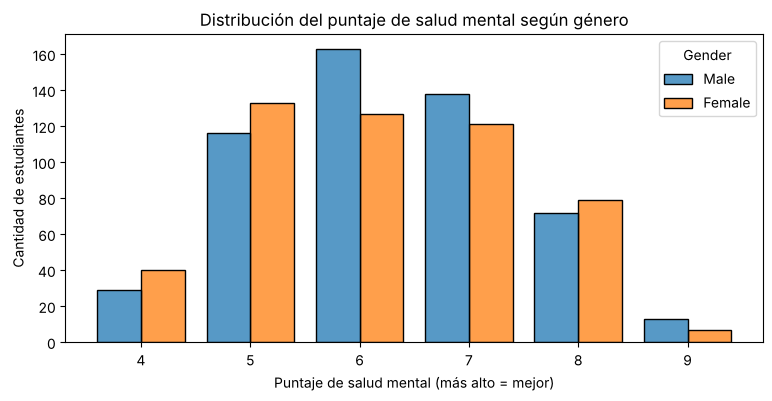

In [53]:
# Histograma comparativo por género (barras lado a lado para cada puntaje)
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x="Mental_Health_Score", hue="Gender", multiple="dodge",
             discrete=True, shrink=0.8, ax=ax)
ax.set_title("Distribución del puntaje de salud mental según género")
ax.set_xlabel("Puntaje de salud mental (más alto = mejor)")
ax.set_ylabel("Cantidad de estudiantes")
plt.show()

**Interpretación:** los puntajes de salud mental de mujeres y varones se reparten de forma muy parecida y van del mismo mínimo al mismo máximo. En ambos casos la mayoría está entre 5 y 7. Se concluye que **no hay una brecha de género importante en salud mental**.

#### Gráfico 5.2 · Salud mental promedio según plataforma

¿Qué plataforma se asocia con mejor o peor salud mental? Se usa un gráfico de barras ordenadas, indicando la cantidad de estudiantes sobre cada una.

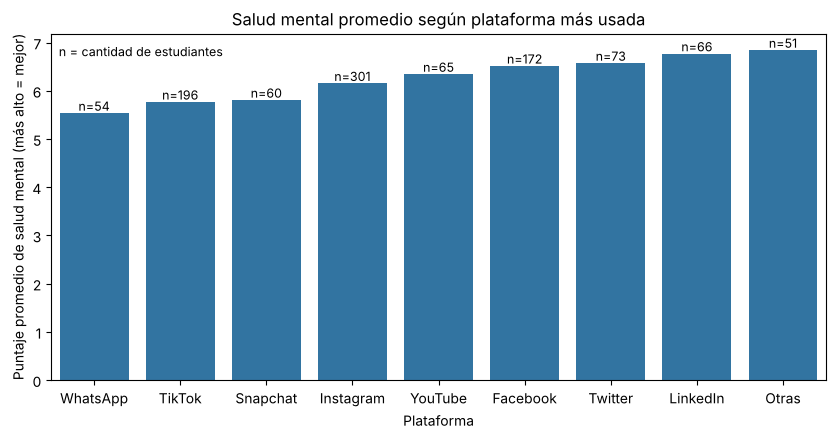

In [54]:
fig, ax = plt.subplots(figsize=(10, 4.5))

# Una barra por plataforma (ya ordenadas de peor a mejor salud mental)
sns.barplot(x=por_plataforma.index, y=por_plataforma["salud_mental"], ax=ax)

# Cantidad de estudiantes sobre cada barra
for i, fila in enumerate(por_plataforma.itertuples()):
    ax.text(i, fila.salud_mental + 0.05, f"n={fila.estudiantes}", ha="center", fontsize=9)

# Referencia para interpretar "n"
ax.text(0.01, 0.97, "n = cantidad de estudiantes", transform=ax.transAxes, va="top", fontsize=9)

ax.set_title("Salud mental promedio según plataforma más usada")
ax.set_xlabel("Plataforma")
ax.set_ylabel("Puntaje promedio de salud mental (más alto = mejor)")
plt.show()

**Interpretación:** los usuarios de **WhatsApp, TikTok y Snapchat** presentan el peor promedio de salud mental, y los de **LinkedIn, Twitter, Facebook y "Otras"**, el mejor. Una posible interpretación es que las plataformas de uso constante y alta frecuencia se asocian con más horas de pantalla, mientras que las de uso más puntual se asocian con menos. Es una hipótesis: no prueba que la plataforma sea la causa.

Cabe destacar que, como el eje arranca en cero, las barras se ven de alturas parecidas y la diferencia (de aproximadamente 5,5 a 6,5 puntos) parece menor de lo que es.

#### Gráfico 5.3 · Horas de uso y salud mental por plataforma

¿Las plataformas en las que los estudiantes pasan más horas tienen peor salud mental? En el diagrama de dispersión cada punto es una plataforma, con sus **horas diarias de uso promedio** en el eje horizontal y su **puntaje promedio de salud mental** en el vertical.

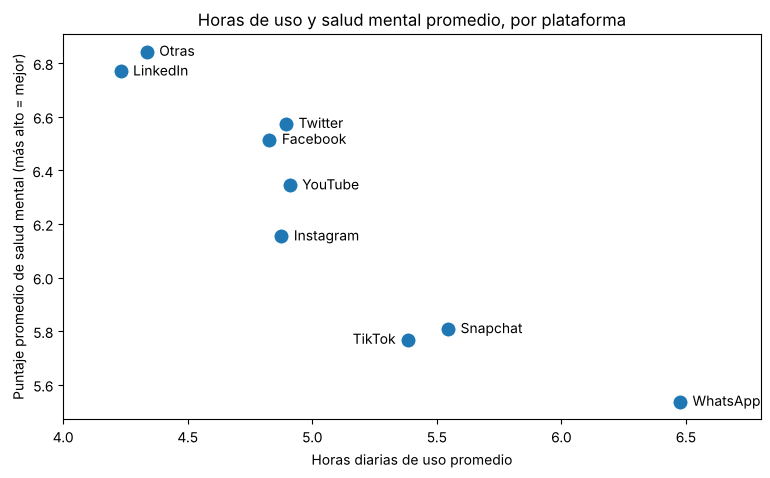

In [55]:
fig, ax = plt.subplots(figsize=(9, 5))

# Un punto por plataforma
sns.scatterplot(data=por_plataforma, x="uso_horas", y="salud_mental", s=120, ax=ax)

# Etiqueta con el nombre de cada plataforma (TikTok a la izquierda para que no tape a Snapchat)
for nombre, fila in por_plataforma.iterrows():
    izq = nombre == "TikTok"
    ax.annotate(nombre, (fila.uso_horas, fila.salud_mental), textcoords="offset points",
                xytext=(-9 if izq else 9, -3), ha="right" if izq else "left", fontsize=10)

ax.set_xlim(4.0, 6.8)    # margen horizontal para que entren las etiquetas
ax.set_title("Horas de uso y salud mental promedio, por plataforma")
ax.set_xlabel("Horas diarias de uso promedio")
ax.set_ylabel("Puntaje promedio de salud mental (más alto = mejor)")
plt.show()

**Interpretación:** los puntos bajan de izquierda a derecha: cuantas más horas de uso promedio tiene una plataforma, menor es la salud mental promedio de sus estudiantes. **WhatsApp** es la que más horas acumula (6,5 h) y la de peor salud mental (5,54). **TikTok** y **Snapchat** están en un uso intermedio (alrededor de 5,4 y 5,5 h) con puntajes bajos (5,77 y 5,81). **LinkedIn** y **"Otras"** tienen el menor uso (alrededor de 4,3 h) y los mejores puntajes (6,77 y 6,84).

El uso diario y la salud mental están relacionados: las plataformas con peor salud mental son también aquellas en las que los estudiantes pasan más horas. Existe una **correlación**, pero no es posible afirmar causalidad.

<a id="8-conclusiones-generales-y-limitaciones"></a>
# 8 | Conclusiones generales y limitaciones

### Conclusiones

1. **El tiempo de uso es el factor común.** En todas las preguntas, los grupos con resultados menos favorables son los que más horas dedican a las redes sociales: más uso se asocia con menos sueño (pregunta 3), peor salud mental (correlación de -0,82, sección 7.2) y mayor afectación académica percibida (pregunta 4).
2. **Edad:** los estudiantes de **18 a 20 años** presentan el perfil más desfavorable entre los grupos etarios.
3. **Nivel de desarrollo:** los estudiantes de **países en desarrollo** usan más las redes, duermen menos y tienen un puntaje de salud mental más bajo que los de países desarrollados.
4. **Sueño y rendimiento:** quienes perciben un impacto académico combinan **más horas de uso y menos horas de sueño**, lo que sugiere que el descanso podría ser un canal relevante del impacto.
5. **Plataformas:** **WhatsApp, TikTok y Snapchat** concentran los peores indicadores; buena parte de la diferencia se explica por las horas de uso, aunque persiste parcialmente al controlarlas.
6. **Género:** no se observa una brecha de género relevante en el impacto; las diferencias aparecen en la elección de plataformas.

### Limitaciones

- **Análisis descriptivo:** los resultados muestran asociaciones dentro de la muestra y no permiten establecer relaciones causales.
- **Tratamiento de duplicados no homogéneo:** las preguntas 1 a 4 utilizan las 1.743 filas originales, mientras que las preguntas 5 y 6 trabajan con los 1.038 registros únicos (ver sección 3.3). Unificar este criterio es la principal mejora pendiente.
- **Tamaños de grupo desbalanceados:** el grupo de 23-24 años, algunas plataformas y ciertas combinaciones plataforma-género tienen pocas observaciones, por lo que sus estadísticos son menos estables.
- **Clasificación del desarrollo:** se basa únicamente en el nivel de ingreso del Banco Mundial, una simplificación de un fenómeno multidimensional.
- **Variables autodeclaradas:** el impacto académico y las horas de uso y sueño son percepciones informadas por los propios estudiantes.